In [1]:
# Mount Google Drive
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [6]:
import os
import json
import joblib
import numpy as np
import pandas as pd

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    roc_auc_score,
    average_precision_score,
    precision_recall_curve,
    roc_curve
)

import matplotlib.pyplot as plt



# غيّر هذا المسار حسب مكان رفع فولدر processed_data في Google Drive
DATA_DIR = "/content/drive/MyDrive/processed_data2"

TRAIN_PATH = os.path.join(DATA_DIR, "train.csv")
TEST_PATH = os.path.join(DATA_DIR, "test.csv")

train = pd.read_csv(TRAIN_PATH)
test = pd.read_csv(TEST_PATH)

print("Train shape:", train.shape)
print("Test shape:", test.shape)

display(train.head())

Train shape: (72270, 27)
Test shape: (1272524, 27)


,step,amount,oldbalanceOrg,newbalanceOrig,oldbalanceDest,newbalanceDest,amount_log,balance_diff_orig,balance_diff_dest,amount_to_orig_balance,...,hour,day,amount_decile,type_encoded,type_CASH_IN,type_CASH_OUT,type_DEBIT,type_PAYMENT,type_TRANSFER,isFraud
0,0.938994,-0.297932,-0.271414,-0.275487,-0.323308,-0.333104,-2.646761,-0.147469,-0.153404,-0.139613,...,0.388547,0.928503,-1.566677,0.952340,-0.530843,-0.736581,-0.080961,1.399013,-0.302366,0
1,0.742253,0.143370,-0.288733,-0.292451,-0.156573,-0.081833,0.910125,-0.144618,0.286075,0.386275,...,-0.536923,0.759631,1.218720,-0.529067,-0.530843,1.357623,-0.080961,-0.714790,-0.302366,0
2,0.601725,-0.274859,-0.250979,-0.260057,-0.323308,-0.333104,-0.700605,-0.242287,-0.153404,-0.139612,...,0.388547,0.590758,-0.870328,0.952340,-0.530843,-0.736581,-0.080961,1.399013,-0.302366,0
3,0.601725,0.656136,-0.176202,-0.292451,-0.058214,0.068715,1.334531,-2.361123,0.555850,-0.139609,...,0.388547,0.590758,1.566894,-0.529067,-0.530843,1.357623,-0.080961,-0.714790,-0.302366,0
4,-1.386754,-0.289718,-0.281171,-0.286818,-0.323308,-0.333104,-1.241340,-0.181224,-0.153404,-0.139612,...,1.545386,-1.435712,-1.218503,0.952340,-0.530843,-0.736581,-0.080961,1.399013,-0.302366,0


In [7]:
# Prepare X/y
TARGET_COL = "isFraud"

X_train = train.drop(columns=[TARGET_COL])
y_train = train[TARGET_COL].astype(int)

X_test = test.drop(columns=[TARGET_COL])
y_test = test[TARGET_COL].astype(int)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)

print("\nTrain target distribution:")
print(y_train.value_counts())

print("\nTest target distribution:")
print(y_test.value_counts())

X_train: (72270, 26)
X_test: (1272524, 26)

Train target distribution:
isFraud
0    65700
1     6570
Name: count, dtype: int64

Test target distribution:
isFraud
0    1270881
1       1643
Name: count, dtype: int64


In [8]:
# اختياري: استخدم كامل test أو عينة منه.
# بالنسبة لـ Logistic Regression و Random Forest غالبًا يمكنك استخدام كامل test.
USE_TEST_SAMPLE = False
TEST_SAMPLE_SIZE = 100_000

if USE_TEST_SAMPLE:
    test_eval = test.sample(
        n=min(TEST_SAMPLE_SIZE, len(test)),
        random_state=42
    )
    X_eval = test_eval.drop(columns=[TARGET_COL])
    y_eval = test_eval[TARGET_COL].astype(int)
else:
    X_eval = X_test
    y_eval = y_test

print("Evaluation shape:", X_eval.shape)
print(y_eval.value_counts())

Evaluation shape: (1272524, 26)
isFraud
0    1270881
1       1643
Name: count, dtype: int64


LogisticRegression(class_weight='balanced', max_iter=1000, n_jobs=-1,
                   random_state=42)
Classification Report:
              precision    recall  f1-score   support

           0     1.0000    0.9997    0.9999   1270881
           1     0.8191    0.9976    0.8996      1643

    accuracy                         0.9997   1272524
   macro avg     0.9095    0.9986    0.9497   1272524
weighted avg     0.9998    0.9997    0.9997   1272524

Confusion Matrix:
[[1270519     362]
 [      4    1639]]
ROC-AUC: 0.999912
PR-AUC:  0.998112


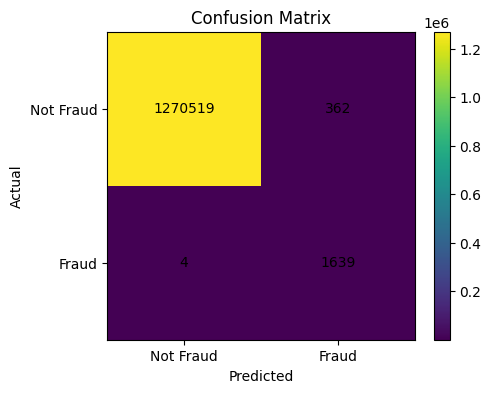

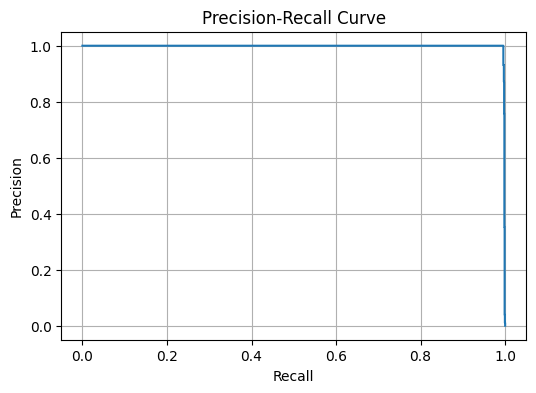

In [9]:
from sklearn.linear_model import LogisticRegression

model = LogisticRegression(
    max_iter=1000,
    class_weight="balanced",
    solver="lbfgs",
    n_jobs=-1,
    random_state=42
)

print(model)

model.fit(X_train, y_train)

y_pred = model.predict(X_eval)

if hasattr(model, "predict_proba"):
    y_score = model.predict_proba(X_eval)[:, 1]
else:
    y_score = model.decision_function(X_eval)


# evaluation
print("Classification Report:")
print(classification_report(y_eval, y_pred, digits=4))

cm = confusion_matrix(y_eval, y_pred)
print("Confusion Matrix:")
print(cm)

roc_auc = roc_auc_score(y_eval, y_score)
pr_auc = average_precision_score(y_eval, y_score)

print(f"ROC-AUC: {roc_auc:.6f}")
print(f"PR-AUC:  {pr_auc:.6f}")




# Confusion Matrix Plot
plt.figure(figsize=(5, 4))
plt.imshow(cm)
plt.title("Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.xticks([0, 1], ["Not Fraud", "Fraud"])
plt.yticks([0, 1], ["Not Fraud", "Fraud"])

for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        plt.text(j, i, cm[i, j], ha="center", va="center")

plt.colorbar()
plt.show()


# percition recall curve
precision, recall, thresholds = precision_recall_curve(y_eval, y_score)

plt.figure(figsize=(6, 4))
plt.plot(recall, precision)
plt.title("Precision-Recall Curve")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.grid(True)
plt.show()

In [10]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    roc_auc_score,
    average_precision_score,
    precision_score,
    recall_score,
    f1_score,
    accuracy_score
)

import pandas as pd
import time
import warnings

warnings.filterwarnings("ignore")

results = []

def evaluate_model(model, model_name):
    print("=" * 80)
    print(model_name)
    print(model)

    start_time = time.time()

    model.fit(X_train, y_train)

    # default threshold = 0.5
    y_pred = model.predict(X_eval)
    y_score = model.predict_proba(X_eval)[:, 1]

    total_time = time.time() - start_time

    print("\nClassification Report:")
    print(classification_report(y_eval, y_pred, digits=4))

    cm = confusion_matrix(y_eval, y_pred)
    print("Confusion Matrix:")
    print(cm)

    tn, fp, fn, tp = cm.ravel()

    accuracy = accuracy_score(y_eval, y_pred)
    precision_fraud = precision_score(y_eval, y_pred, pos_label=1, zero_division=0)
    recall_fraud = recall_score(y_eval, y_pred, pos_label=1, zero_division=0)
    f1_fraud = f1_score(y_eval, y_pred, pos_label=1, zero_division=0)
    roc_auc = roc_auc_score(y_eval, y_score)
    pr_auc = average_precision_score(y_eval, y_score)

    print(f"Accuracy: {accuracy:.10f}")
    print(f"ROC-AUC:  {roc_auc:.6f}")
    print(f"PR-AUC:   {pr_auc:.6f}")
    print(f"Time:     {total_time:.2f} seconds")

    results.append({
        "model_name": model_name,
        "solver": model.solver,
        "penalty": model.penalty,
        "C": model.C,
        "class_weight": str(model.class_weight),
        "accuracy": accuracy,
        "precision_fraud": precision_fraud,
        "recall_fraud": recall_fraud,
        "f1_fraud": f1_fraud,
        "roc_auc": roc_auc,
        "pr_auc": pr_auc,
        "TN": tn,
        "FP": fp,
        "FN": fn,
        "TP": tp,
        "time_seconds": total_time
    })

    return model

In [11]:
model1 = LogisticRegression(
    max_iter=1000,
    class_weight="balanced",
    solver="lbfgs",
    penalty="l2",
    C=1.0,
    n_jobs=-1,
    random_state=42
)

model1 = evaluate_model(
    model1,
    "Model 1 - Baseline balanced C=1"
)

Model 1 - Baseline balanced C=1
LogisticRegression(class_weight='balanced', max_iter=1000, n_jobs=-1,
                   random_state=42)

Classification Report:
              precision    recall  f1-score   support

           0     1.0000    0.9997    0.9999   1270881
           1     0.8191    0.9976    0.8996      1643

    accuracy                         0.9997   1272524
   macro avg     0.9095    0.9986    0.9497   1272524
weighted avg     0.9998    0.9997    0.9997   1272524

Confusion Matrix:
[[1270519     362]
 [      4    1639]]
Accuracy: 0.9997123826
ROC-AUC:  0.999912
PR-AUC:   0.998112
Time:     1.78 seconds


In [12]:
model2 = LogisticRegression(
    max_iter=1000,
    class_weight="balanced",
    solver="lbfgs",
    penalty="l2",
    C=0.1,
    n_jobs=-1,
    random_state=42
)

model2 = evaluate_model(
    model2,
    "Model 2 - Stronger regularization C=0.1"
)

Model 2 - Stronger regularization C=0.1
LogisticRegression(C=0.1, class_weight='balanced', max_iter=1000, n_jobs=-1,
                   random_state=42)

Classification Report:
              precision    recall  f1-score   support

           0     1.0000    0.9999    1.0000   1270881
           1     0.9585    0.9976    0.9776      1643

    accuracy                         0.9999   1272524
   macro avg     0.9792    0.9988    0.9888   1272524
weighted avg     0.9999    0.9999    0.9999   1272524

Confusion Matrix:
[[1270810      71]
 [      4    1639]]
Accuracy: 0.9999410620
ROC-AUC:  0.999861
PR-AUC:   0.998138
Time:     1.45 seconds


In [13]:
model3 = LogisticRegression(
    max_iter=1000,
    class_weight="balanced",
    solver="lbfgs",
    penalty="l2",
    C=10.0,
    n_jobs=-1,
    random_state=42
)

model3 = evaluate_model(
    model3,
    "Model 3 - Weaker regularization C=10"
)

Model 3 - Weaker regularization C=10
LogisticRegression(C=10.0, class_weight='balanced', max_iter=1000, n_jobs=-1,
                   random_state=42)

Classification Report:
              precision    recall  f1-score   support

           0     1.0000    0.9996    0.9998   1270881
           1     0.7831    0.9976    0.8774      1643

    accuracy                         0.9996   1272524
   macro avg     0.8915    0.9986    0.9386   1272524
weighted avg     0.9997    0.9996    0.9997   1272524

Confusion Matrix:
[[1270427     454]
 [      4    1639]]
Accuracy: 0.9996400854
ROC-AUC:  0.999911
PR-AUC:   0.998061
Time:     1.66 seconds


In [14]:
model4 = LogisticRegression(
    max_iter=1000,
    class_weight=None,
    solver="lbfgs",
    penalty="l2",
    C=1.0,
    n_jobs=-1,
    random_state=42
)

model4 = evaluate_model(
    model4,
    "Model 4 - Without class_weight"
)

Model 4 - Without class_weight
LogisticRegression(max_iter=1000, n_jobs=-1, random_state=42)

Classification Report:
              precision    recall  f1-score   support

           0     1.0000    1.0000    1.0000   1270881
           1     0.9951    0.9976    0.9964      1643

    accuracy                         1.0000   1272524
   macro avg     0.9976    0.9988    0.9982   1272524
weighted avg     1.0000    1.0000    1.0000   1272524

Confusion Matrix:
[[1270873       8]
 [      4    1639]]
Accuracy: 0.9999905699
ROC-AUC:  0.999855
PR-AUC:   0.998259
Time:     1.32 seconds


In [15]:
model5 = LogisticRegression(
    max_iter=1000,
    class_weight="balanced",
    solver="liblinear",
    penalty="l1",
    C=1.0,
    random_state=42
)

model5 = evaluate_model(
    model5,
    "Model 5 - L1 regularization liblinear"
)

Model 5 - L1 regularization liblinear
LogisticRegression(class_weight='balanced', max_iter=1000, penalty='l1',
                   random_state=42, solver='liblinear')

Classification Report:
              precision    recall  f1-score   support

           0     1.0000    0.9997    0.9998   1270881
           1     0.8114    0.9976    0.8949      1643

    accuracy                         0.9997   1272524
   macro avg     0.9057    0.9986    0.9474   1272524
weighted avg     0.9998    0.9997    0.9997   1272524

Confusion Matrix:
[[1270500     381]
 [      4    1639]]
Accuracy: 0.9996974517
ROC-AUC:  0.999908
PR-AUC:   0.998146
Time:     3.83 seconds


In [16]:
model6 = LogisticRegression(
    max_iter=1000,
    class_weight="balanced",
    solver="liblinear",
    penalty="l2",
    C=1.0,
    random_state=42
)

model6 = evaluate_model(
    model6,
    "Model 6 - L2 liblinear"
)

Model 6 - L2 liblinear
LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42,
                   solver='liblinear')

Classification Report:
              precision    recall  f1-score   support

           0     1.0000    0.9997    0.9999   1270881
           1     0.8228    0.9976    0.9018      1643

    accuracy                         0.9997   1272524
   macro avg     0.9114    0.9986    0.9508   1272524
weighted avg     0.9998    0.9997    0.9997   1272524

Confusion Matrix:
[[1270528     353]
 [      4    1639]]
Accuracy: 0.9997194552
ROC-AUC:  0.999899
PR-AUC:   0.998148
Time:     2.26 seconds


In [17]:
import joblib
import os

MODEL_DIR = "/content/drive/MyDrive/processed_data2/saved_models"
os.makedirs(MODEL_DIR, exist_ok=True)

model4_path = os.path.join(
    MODEL_DIR,
    "logistic_regression_model4_without_class_weight.joblib"
)

joblib.dump(model4, model4_path)

print("Model 4 saved successfully:")
print(model4_path)

Model 4 saved successfully:
/content/drive/MyDrive/processed_data2/saved_models/logistic_regression_model4_without_class_weight.joblib
